In [1]:
# Imports

import os
import entsoe
import pandas as pd
from entsoe import EntsoePandasClient
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor


In [2]:
# Fetch Client API key

api_key = os.environ.get('ENTSOE_API_KEY')
if api_key is None:
    raise ValueError('ENTSOE_API_KEY environment variable not set')

client = EntsoePandasClient(api_key=api_key)

In [3]:
# Timelines

# 2023
start_2023 = pd.Timestamp('2023-01-01', tz='Europe/Lisbon')
end_2023 = pd.Timestamp('2024-01-01', tz='Europe/Lisbon')

# 2024
start_2024 = pd.Timestamp('2024-01-01', tz='Europe/Lisbon')
end_2024 = pd.Timestamp('2025-01-01', tz='Europe/Lisbon')

# 2025
start_2025 = pd.Timestamp('2025-01-01', tz='Europe/Lisbon')
end_2025 = pd.Timestamp('2026-01-01', tz='Europe/Lisbon')

# Prices

Day-ahead prices are retrieved year-by-year via the ENTSO-E API. From September 30, 2025 onwards, Portugal's day-ahead market resolution shifted from hourly to 15-minute intervals, so the 2025 data arrives at mixed resolution. After concatenating all three years, duplicate timestamps introduced by the API's internal request padding and by the autumn DST clock change are removed, and the combined series is resampled to hourly (via mean) to match the resolution of the generation and load data.

In [5]:
# 2023
prices_2023 = client.query_day_ahead_prices('PT',start=start_2023,end=end_2023)
prices_2023.index = prices_2023.index.tz_localize(None)
prices_2023 = prices_2023.to_frame(name='Day-ahead Price (EUR/MWh)')
prices_2023.index.name = 'Time Stamp'
#print(prices_2023.shape);
#print(prices_2023.head());
#print(prices_2023.tail());

In [6]:
# 2024
prices_2024 = client.query_day_ahead_prices('PT',start=start_2024,end=end_2024)
prices_2024.index = prices_2024.index.tz_localize(None)
prices_2024 = prices_2024.to_frame(name='Day-ahead Price (EUR/MWh)')
prices_2024.index.name = 'Time Stamp'
#print(prices_2024.shape);
#print(prices_2024.head());
#print(prices_2024.tail());

In [7]:
# 2025
prices_2025 = client.query_day_ahead_prices('PT',start=start_2025,end=end_2025)
prices_2025.index = prices_2025.index.tz_localize(None)
prices_2025 = prices_2025.to_frame(name='Day-ahead Price (EUR/MWh)')
prices_2025.index.name = 'Time Stamp'
#print(prices_2025.shape);
#print(prices_2025.head());
#print(prices_2025.tail());

In [8]:
# Merge all three years

df_price = pd.concat([prices_2023, prices_2024, prices_2025]).sort_index()

#print(df_price.shape)
#print(df_price.index.duplicated().sum());

In [9]:
# Adjust to hourly resolution

df_price = df_price[~df_price.index.duplicated(keep='first')]
#print(df_price.shape);
#print(df_price.index.duplicated().sum());

df_price_hourly = df_price.resample("h").mean()
price_all = df_price_hourly[(df_price_hourly.index >= "2023-01-01") & (df_price_hourly.index < "2026-01-01")]
#print(price_all.shape);

# Generation

Actual generation per production type is retrieved the same way as prices, pulled year-by-year via the ENTSO-E API. The raw response includes both `Actual Aggregated` (true generation) and, for storage-capable types, `Actual Consumption` (energy drawn from the grid, e.g. pumped hydro pumping water uphill). Only `Actual Aggregated` columns are retained, since consumption values represent grid draw rather than production and would distort renewable share calculations if included.

In [10]:
# 2023
gen_2023 = client.query_generation('PT',start=start_2023, end=end_2023) # Get data
gen_2023 = gen_2023.loc[:,gen_2023.columns.get_level_values(1) == 'Actual Aggregated'] # Get data that represents actual generation
gen_2023.columns = gen_2023.columns.get_level_values(0) # Simplify columns to production type name
gen_2023.index = gen_2023.index.tz_localize(None) # Remove Timezone
gen_2023.index.name = 'Time Stamp'

#print(gen_2023.shape);
#print(gen_2023.head());
#print(gen_2023.tail());

In [11]:
# 2024
gen_2024 = client.query_generation('PT',start=start_2024, end=end_2024)
gen_2024 = gen_2024.loc[:,gen_2024.columns.get_level_values(1) == 'Actual Aggregated']
gen_2024.columns = gen_2024.columns.get_level_values(0)
gen_2024.index = gen_2024.index.tz_localize(None)
gen_2024.index.name = 'Time Stamp'

#print(gen_2024.shape);
#print(gen_2024.head());
#print(gen_2024.tail());

In [12]:
# 2025
gen_2025 = client.query_generation('PT',start=start_2025, end=end_2025)
gen_2025 = gen_2025.loc[:,gen_2025.columns.get_level_values(1) == 'Actual Aggregated']
gen_2025.columns = gen_2025.columns.get_level_values(0)
gen_2025.index = gen_2025.index.tz_localize(None)
gen_2025.index.name = 'Time Stamp'

#print(gen_2025.shape);
#print(gen_2025.head());
#print(gen_2025.tail());

In [13]:
# Concatenate all three years

gen_all = pd.concat([gen_2023, gen_2024, gen_2025])
gen_all = gen_all.sort_index()
gen_all = gen_all[~gen_all.index.duplicated(keep='first')]
#print(gen_all.shape);
#print(gen_all.duplicated().sum()); # Check for duplicates
#print(gen_all.head());
#print(gen_all.tail());


# Load

Actual total load is retrieved the same way, year-by-year via the ENTSO-E API. Unlike prices, load is reported consistently at hourly resolution across all three years, so no resampling is needed. The same autumn DST duplicate-timestamp issue appears here (one duplicate hour per year) and is resolved by keeping the first occurrence. Only actual load is used in this analysis; the day-ahead load forecast, also available from ENTSO-E, was not pulled since it isn't used in any of the modeling or arbitrage calculations below.

In [14]:
# 2023
load_2023 = client.query_load('PT', start=start_2023, end=end_2023)
load_2023.index = load_2023.index.tz_localize(None)
load_2023.index.name = 'Time Stamp'

#print(load_2023.shape)
#print(load_2023.head())
#print(load_2023.tail())

In [15]:
# 2024
load_2024 = client.query_load('PT', start=start_2024, end=end_2024)
load_2024.index = load_2024.index.tz_localize(None)
load_2024.index.name = 'Time Stamp'

#print(load_2024.shape)
#print(load_2024.head())
#print(load_2024.tail())

In [16]:
# 2025
load_2025 = client.query_load('PT', start=start_2025, end=end_2025)
load_2025.index = load_2025.index.tz_localize(None)
load_2025.index.name = 'Time Stamp'

#print(load_2025.shape)
#print(load_2025.head())
#print(load_2025.tail())

In [17]:
# Concatenate all three years
load_all = pd.concat([load_2023, load_2024, load_2025])
load_all = load_all.sort_index()

load_all = load_all[~load_all.index.duplicated(keep='first')]
#print(load_all.shape)
#print(load_all.index.duplicated().sum()) # Check for duplicates
#print(load_all.head())
#print(load_all.tail())


# Final Data Set

## Merging the Datasets

Price, generation, and load are combined into a single hourly dataset on a shared datetime index. Two DST-related edge cases were identified and handled during this process:
- **Autumn clock change**: the 01:00–02:00 hour occurs twice in local time, producing duplicate timestamps. The first occurrence is kept.
- **Spring clock change**: the 01:00–02:00 hour does not occur at all in local time, producing rows with no corresponding data. These rows (3 across the full period) are dropped.

The final merged dataset spans January 1, 2023 to December 31, 2025 at hourly resolution.

In [18]:
df_all = price_all.join(gen_all).join(load_all);

df_all_clean = df_all.dropna();
#print(df_all_clean.shape);
#print(df_all_clean.head());
#print(df_all_clean.tail());

In [ ]:
#df_all_clean.to_csv('portugal_energy_clean')

## Renewable Share

Renewable generation is defined as the sum of Biomass, Hydro (run-of-river and reservoir), Solar, and Wind (onshore and offshore). Hydro Pumped Storage is excluded, as it represents energy storage rather than primary generation. Renewable share is calculated as renewable generation divided by total generation for each hour.

In [20]:
renewable_cols = ['Biomass', 'Hydro Run-of-river and pondage', 'Hydro Water Reservoir', 'Solar', 'Wind Offshore', 'Wind Onshore']
non_renewable_cols = ['Fossil Gas', 'Fossil Hard coal', 'Hydro Pumped Storage', 'Other']

df_all_clean['Total Generation'] = df_all_clean[renewable_cols + non_renewable_cols].sum(axis=1)
df_all_clean['Renewable Generation'] = df_all_clean[renewable_cols].sum(axis=1)
df_all_clean['Renewable Share Pct'] = (df_all_clean['Renewable Generation'] / df_all_clean['Total Generation'])*100

print(df_all_clean['Renewable Share Pct'].describe())

correlation = df_all_clean['Day-ahead Price (EUR/MWh)'].corr(df_all_clean['Renewable Share Pct'])
print(f'Correlation: {correlation:.3f}')

count    26301.000000
mean        70.561312
std         15.368986
min         17.388393
25%         59.498222
50%         72.690176
75%         82.693448
max         98.035755
Name: Renewable Share Pct, dtype: float64
Correlation: -0.667


### Exploratory Analysis: Price and Renewable Share

Renewable share and day-ahead price show a correlation of -0.667 across the full 3-year period. Visualizing the relationship reveals it is non-linear: price variance widens substantially above ~50% renewable share, and near-zero pricing is concentrated almost exclusively above ~65% renewable share, occurring predominantly during spring (March–April) middays. Year-over-year comparison shows this pattern intensified from 2023 (negligible) to 2024 (peak) to 2025, consistent with continued renewable capacity growth outpacing demand during low-demand periods.

### Plots

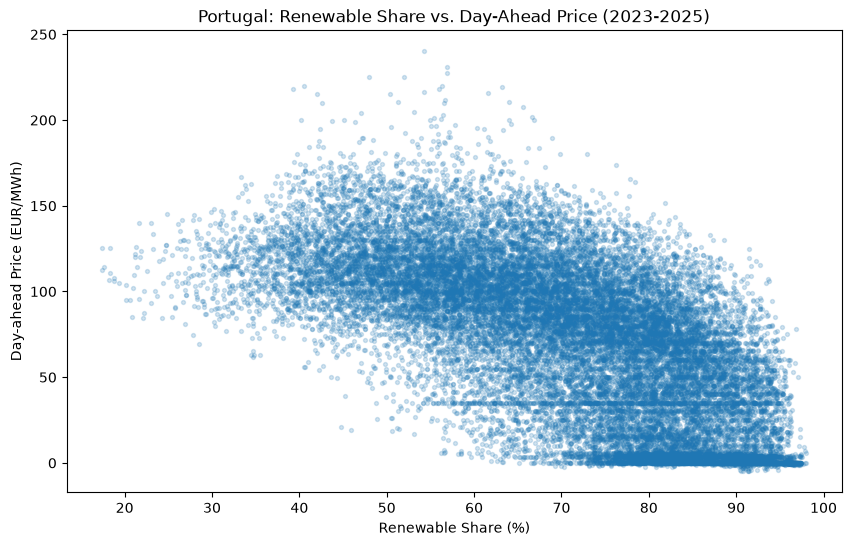

In [21]:
plt.figure(figsize=(10, 6))
plt.scatter(df_all_clean['Renewable Share Pct'], df_all_clean['Day-ahead Price (EUR/MWh)'], alpha=0.2, s=8)
plt.xlabel('Renewable Share (%)')
plt.ylabel('Day-ahead Price (EUR/MWh)')
plt.title('Portugal: Renewable Share vs. Day-Ahead Price (2023-2025)')
plt.show()

In [22]:
zero_or_negative = df_all_clean[df_all_clean['Day-ahead Price (EUR/MWh)'] <= 0].copy();
zero_or_negative['year'] = zero_or_negative.index.year;
zero_or_negative['month'] = zero_or_negative.index.month;
zero_or_negative['hour'] = zero_or_negative.index.hour;

([<matplotlib.axis.YTick at 0x172554c0710>,
 [Text(0, 0, '2023'), Text(0, 1, '2024'), Text(0, 2, '2025')])

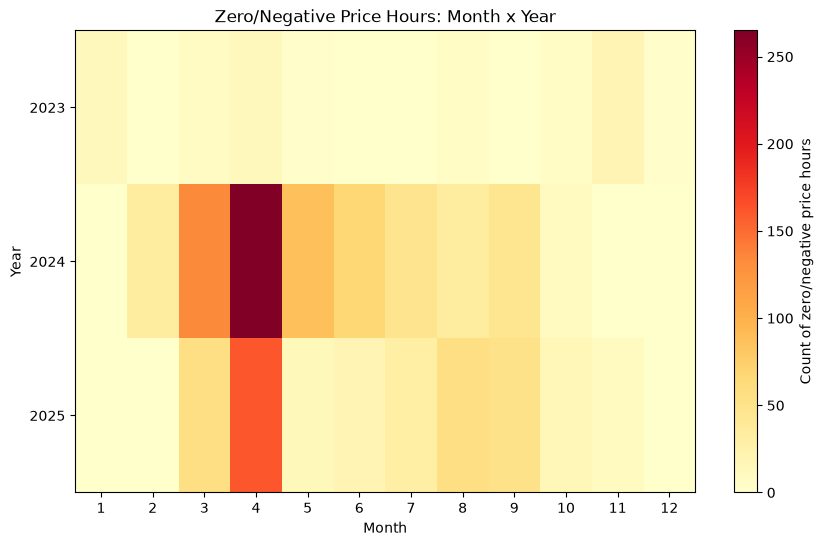

In [23]:
pivot_year_month = zero_or_negative.pivot_table(index='year', columns='month',aggfunc='size',fill_value=0)

plt.figure(figsize=(10,6))
plt.imshow(pivot_year_month, aspect='auto', cmap='YlOrRd')
plt.colorbar(label='Count of zero/negative price hours')
plt.xlabel('Month')
plt.ylabel('Year')
plt.title('Zero/Negative Price Hours: Month x Year')
plt.xticks(range(len(pivot_year_month.columns)),pivot_year_month.columns)
plt.yticks(range(len(pivot_year_month.index)),pivot_year_month.index)

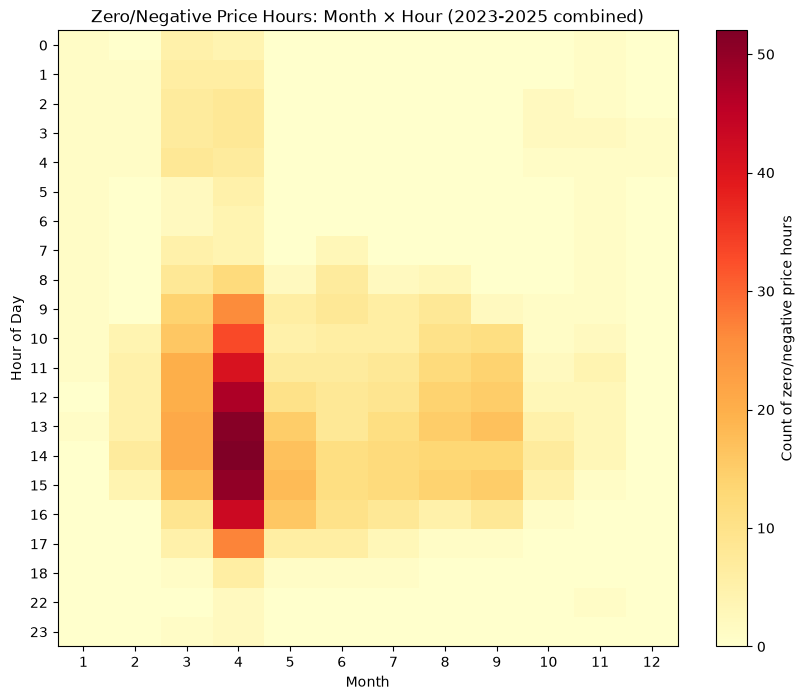

In [24]:
pivot_month_hour = zero_or_negative.pivot_table(index='hour', columns='month', aggfunc='size', fill_value=0)

plt.figure(figsize=(10, 8))
plt.imshow(pivot_month_hour, aspect='auto', cmap='YlOrRd')
plt.colorbar(label='Count of zero/negative price hours')
plt.xlabel('Month')
plt.ylabel('Hour of Day')
plt.title('Zero/Negative Price Hours: Month × Hour (2023-2025 combined)')
plt.xticks(range(len(pivot_month_hour.columns)), pivot_month_hour.columns)
plt.yticks(range(len(pivot_month_hour.index)), pivot_month_hour.index)
plt.show()

## Regression Model

In [25]:
df_model = df_all_clean.copy()
df_model['hour'] = df_model.index.hour
df_model['month'] = df_model.index.month
df_model['year'] = df_model.index.year

#print(df_model[['Day-ahead Price (EUR/MWh)','Renewable Share Pct', 'Actual Load', 'hour', 'month', 'year']].head())

In [26]:
features = ['Renewable Share Pct','Actual Load', 'hour', 'month', 'year']
X = df_model[features]
y = df_model['Day-ahead Price (EUR/MWh)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#print(X_train.shape, X_test.shape)

### Predictive Modeling

To move beyond correlation, price is modeled as a function of renewable share, load, hour, month, and year. A linear regression establishes a baseline; because the exploratory analysis suggested non-linear relationships (particularly for hour and month), a Random Forest is also tested to capture interactions and non-linearities the linear model cannot.

In [27]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Intercept: ', model.intercept_)
print('Coefficients:')
for feature, coef in zip(features,model.coef_):
    print(f' {feature}:{coef:.3f}')

Intercept:  17655.675706106478
Coefficients:
 Renewable Share Pct:-1.876
 Actual Load:0.011
 hour:-0.680
 month:0.520
 year:-8.652


In [28]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"R² score: {r2:.3f}")
print(f"Mean Absolute Error: {mae:.2f} EUR/MWh")

R² score: 0.513
Mean Absolute Error: 26.07 EUR/MWh


The linear model explains only 51.3% of price variance (R² = 0.513, MAE = €26.07/MWh). Given the known non-linear seasonal and diurnal patterns in the data, a Random Forest is tested next to see how much of the unexplained variance is attributable to relationships a straight-line model cannot capture.

In [29]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train);

In [30]:
y_pred_rf = rf_model.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest R²: {r2_rf:.3f}")
print(f"Random Forest MAE: {mae_rf:.2f} EUR/MWh")

importances = pd.Series(rf_model.feature_importances_, index=features)
print(importances.sort_values(ascending=False))

Random Forest R²: 0.774
Random Forest MAE: 15.87 EUR/MWh
Renewable Share Pct    0.559015
month                  0.154129
Actual Load            0.120440
year                   0.105085
hour                   0.061331
dtype: float64


The Random Forest substantially outperforms the linear model (R² = 0.774, MAE = €15.88/MWh), confirming that non-linear time-of-day and seasonal effects account for a meaningful share of price variance. Renewable share remains the dominant predictor by a wide margin (55.9% feature importance), consistent with the exploratory findings above.

## Battery Storage Value

To translate these pricing dynamics into a concrete economic signal, a theoretical battery arbitrage model estimates the value of storage under this price behavior. A 1 MW / 4 MWh battery (90% round-trip efficiency) is modeled charging during each day's 4 cheapest hours and discharging during its 4 priciest hours — a simplified strategy assuming perfect foresight and no charge/discharge sequencing constraint, representing a theoretical upper bound rather than an achievable real-world dispatch.

In [31]:
def daily_arbitrage_profit(day_prices, energy_mwh=4, efficiency=0.90):
    cheapest_4 = day_prices.nsmallest(4)
    priciest_4 = day_prices.nlargest(4)
    cost_to_charge = cheapest_4.mean() * energy_mwh
    revenue_from_discharge = priciest_4.mean() * energy_mwh * efficiency
    return revenue_from_discharge - cost_to_charge

daily_profits = df_all_clean.groupby(df_all_clean.index.date)['Day-ahead Price (EUR/MWh)'].apply(daily_arbitrage_profit)
#print(daily_profits.head())
print(f"\nTotal 3-year profit: €{daily_profits.sum():,.2f}")
print(f"Average daily profit: €{daily_profits.mean():.2f}")


Total 3-year profit: €243,226.69
Average daily profit: €221.92


In [32]:
annual_profit = daily_profits.sum() / 3  # 3 years
profit_per_mwh_capacity = annual_profit / 4  # 4 MWh battery
print(f"Annual profit: €{annual_profit:,.2f}")
print(f"Annual profit per MWh of capacity: €{profit_per_mwh_capacity:,.2f}/MWh")

Annual profit: €81,075.56
Annual profit per MWh of capacity: €20,268.89/MWh


In [33]:
daily_profits_df = daily_profits.to_frame(name='profit')
daily_profits_df.index = pd.to_datetime(daily_profits_df.index)
daily_profits_df['year'] = daily_profits_df.index.year
print(daily_profits_df.groupby('year')['profit'].agg(['mean', 'sum']))

            mean           sum
year                          
2023  189.831296   69288.42300
2024  196.333847   71858.18800
2025  279.671445  102080.07725


# Conclusion

Arbitrage value rose from €69,288/year (2023) to €102,080/year (2025), a ~47% increase tracking the same renewable-driven volatility growth identified in the exploratory analysis. This suggests that as Portugal's grid adds renewable capacity, both curtailment risk and battery storage investment value are increasing together — a pattern directly relevant to grid-scale storage investment timing.